<a href="https://colab.research.google.com/github/mahizhavarthinir/facial-emotion-detection./blob/main/Copy_of_Face_Expression_Recognition_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Facial Expression Recognition Using Convolutional Neural Networks (CNN)**

**STEP 1: IMPORT THE** **LIBRARIES**

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os

print("TensorFlow:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow: 2.20.0
Libraries imported successfully!


In [ ]:
print(os.listdir("/content"))

['.config', 'sample_data']


WE CHECK OUR COLAB CONTAINS ANY DATASET BEFORE WE UPLOAD OUR ACTUAL CK_PLUS DATASET.

**STEP 2: UPLOAD THE DATASET**

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving CK_plus.zip to CK_plus.zip


**STEP 3:EXTRACT ZIPPED FILE**

In [ ]:
!unzip -q CK_plus.zip -d CK_plus

**STEP 4: WHAT ARE THE CLASSES WE HAVE**

In [ ]:
import os

print(os.listdir("/content/CK_plus"))

['happy', 'anger', 'fear', 'disgust', 'contempt', 'sadness', 'surprise']


OUR DATASET HAVE 7 DIFFERENT EMOTIONS
anger
sadness
happy
surprise
disgust
contempt
fear

**STEP 5:COUNT THE IMAGES**

In [ ]:
import os

dataset_path = "/content/CK_plus"

for emotion in os.listdir(dataset_path):
    emotion_path = os.path.join(dataset_path, emotion)

    if os.path.isdir(emotion_path):
        count = len(os.listdir(emotion_path))
        print(emotion, ":", count)


happy : 207
anger : 135
fear : 75
disgust : 177
contempt : 54
sadness : 84
surprise : 249


**BASED ON THIS STEP 5 WE KNOW OUR DATASET CONTAINS 981 IMAGES **

**STEP 6: DISPALY THE SAMPLE IMAGES**

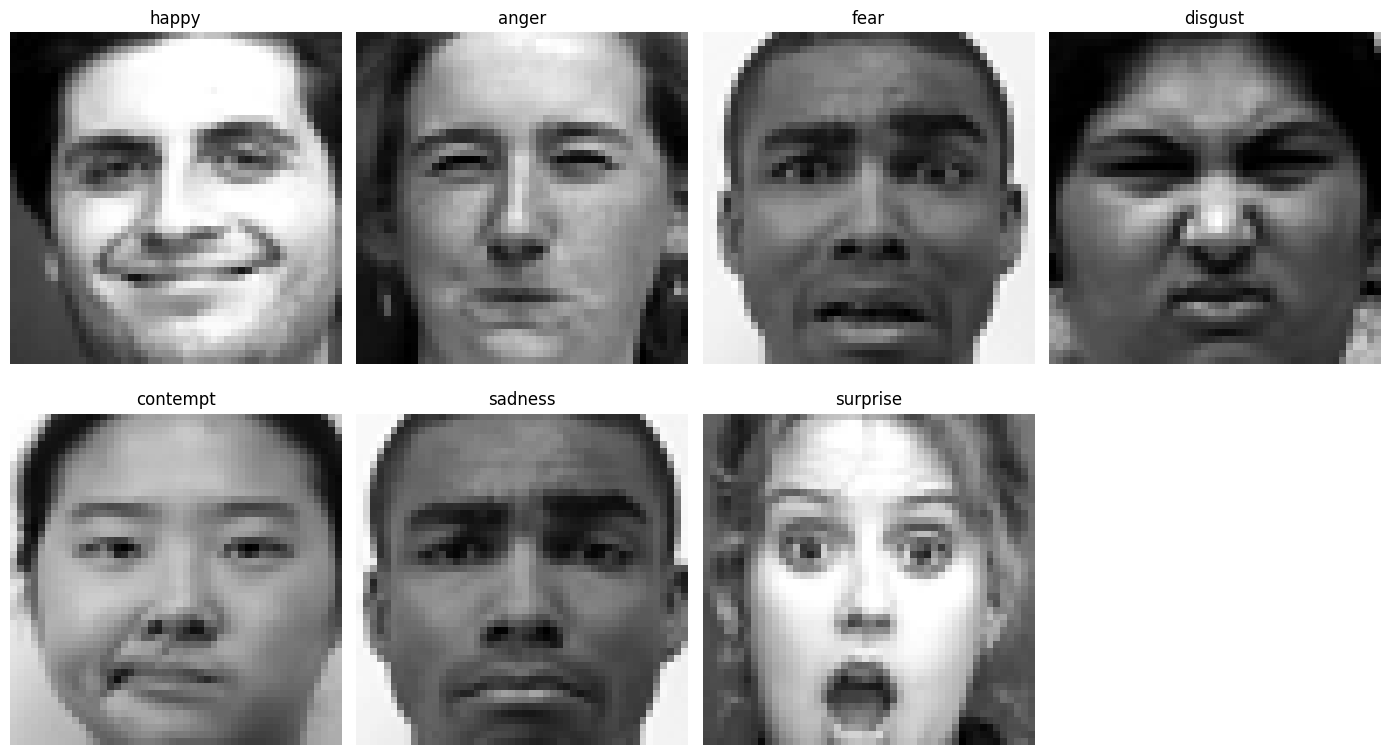

In [ ]:
import matplotlib.pyplot as plt
import os
import random

dataset_path = "/content/CK_plus"

emotions = os.listdir(dataset_path)

plt.figure(figsize=(14, 8))

for i, emotion in enumerate(emotions):
    emotion_path = os.path.join(dataset_path, emotion)
    image_name = random.choice(os.listdir(emotion_path))
    image_path = os.path.join(emotion_path, image_name)

    image = plt.imread(image_path)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(emotion)
    plt.axis("off")

plt.tight_layout()
plt.show()

Before training, we should visually check the images and confirm that each folder really contains facial-expression images.
Face image → CNN → happy
Face image → CNN → anger
Face image → CNN → sadness
...
So, label = the category/class that tells the CNN what the image represents.

**STEP 7:CHECK IMAGE SIZE AND FORMAT**

In [ ]:
from PIL import Image
import os

dataset_path = "/content/CK_plus"

emotions = sorted(os.listdir(dataset_path))

for emotion in emotions:
    folder_path = os.path.join(dataset_path, emotion)

    files = os.listdir(folder_path)

    # Take first image
    image_path = os.path.join(folder_path, files[0])

    image = Image.open(image_path)

    print(emotion, "->",
          "Size:", image.size,
          "Mode:", image.mode,
          "Images:", len(files))

anger -> Size: (48, 48) Mode: L Images: 135
contempt -> Size: (48, 48) Mode: L Images: 54
disgust -> Size: (48, 48) Mode: L Images: 177
fear -> Size: (48, 48) Mode: L Images: 75
happy -> Size: (48, 48) Mode: L Images: 207
sadness -> Size: (48, 48) Mode: L Images: 84
surprise -> Size: (48, 48) Mode: L Images: 249


Before loading all images into the CNN, we need to know:

Image dimensions
Image format (JPG/PNG)
Whether images are grayscale or RGB
Your CNN needs all images to have the same size.
Original images
      ↓
Different sizes
      ↓
Resize
      ↓
48 × 48
      ↓
CNN

Grayscale → 1 channel
RGB-> 3 channel
pixel:
grayscale:128
RGB->(120,80,200)
**FOR DATASET CONTAINS GRAYSCALE:**
CK+ grayscale image
       ↓
48 × 48 × 1
       ↓
CNN
       ↓
7 facial-expression classes

**STEP 8:LOAD AND PREPROCESS ALL IMAGES**

In [ ]:
import cv2
import numpy as np
import os

dataset_path = "/content/CK_plus"

emotions = sorted(os.listdir(dataset_path))

X = []
y = []

IMG_SIZE = 48

for label, emotion in enumerate(emotions):

    folder_path = os.path.join(dataset_path, emotion)

    for image_name in os.listdir(folder_path):

        image_path = os.path.join(folder_path, image_name)

        # Read image as grayscale
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        # Resize to 48 × 48
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))

        # Normalize pixel values: 0-255 → 0-1
        image = image / 255.0

        X.append(image)
        y.append(label)

X = np.array(X)
y = np.array(y)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", emotions)

Images shape: (981, 48, 48)
Labels shape: (981,)
Classes: ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']


**HERE WE WILL DO MAINLY 4 THINGS**
Read every image
Convert to grayscale
Resize to 48 × 48
Normalize pixel values from 0–255 → 0–1
Original image
     ↓
Grayscale
     ↓
48 × 48
     ↓
Normalize
     ↓
CNN-ready image
**THE ABOVE CODE **
X->Images
Y->Lables

**FOR UNDERSTANDING THE TOPIC WE INCLUDE **
**NOTE: **
NORMALISING:
Range->(0-255)to(0-1)
Usually an image uses 8-bit (8-bit unsigned integer) representation.
2⁸ = 256 values
0, 1, 2, 3, ... 254, 255
0   → Black
255 → White
128 → Middle gray
why we convert (0-255)to(0-1)
image = image / 255.0
Original       After normalization

0       /255   = 0.0
128     /255   = 0.502
255     /255   = 1.0
if 0.5 means it comes under 50%
After normalization:(0-1)
the values are smaller and on a consistent scale, which generally makes neural-network training more stable and easier to optimize.255 is the maximum brightness value for an 8-bit grayscale image, so dividing by 255 converts every pixel into a standard 0–1 range.

**STEP 9: PREPARE THE DATA FOR CNN**

In [ ]:
from sklearn.model_selection import train_test_split

# Add grayscale channel
X = X.reshape(X.shape[0], 48, 48, 1)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training images: (784, 48, 48, 1)
Testing images: (197, 48, 48, 1)
Training labels: (784,)
Testing labels: (197,)


**We will use 80% training and 20% testing.**
stratify=y When you split the data, keep approximately the same proportion of each label in both training and testing."

**lables calculation:**
981 × 80% ≈ 784
981 × 20% ≈ 197
 **Why Split the test and train the dataset:**
981 images
    ↓
Training data → CNN learns from these
    ↓
Testing data → Check how well it works on unseen images
But CNN expects grayscale images in this form:
(number of images, height, width, channels)
(981, 48, 48)
        ↓
(981, 48, 48, 1)

**STEP 10: Build the CNN Model**

In [ ]:
# Note: The AttributeError: module 'cv2' has no attribute 'CascadeClassifier' reported
# is occurring in cell azr1YS6DTCU-, not this cell. To fix it, consider reinstalling
# opencv-python-headless in a separate cell and restarting the runtime.

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

model = Sequential([

    # First convolution layer
    Conv2D(32, (3, 3), activation="relu", input_shape=(48, 48, 1)),
    MaxPooling2D((2, 2)),

    # Second convolution layer
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Convert feature maps into a single vector
    Flatten(),

    # Fully connected layer
    Dense(128, activation="relu"),

    # Reduce overfitting
    Dropout(0.5),

    # Output layer - 7 expression classes
    Dense(7, activation="softmax")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 839,047 (3.20 MB)

 Trainable params: 839,047 (3.20 MB)

 Non-trainable params: 0 (0.00 B)

48 × 48 grayscale face
          ↓
      CNN layers
          ↓
   learned features
          ↓
     7 outputs
          ↓
expression class
Our Model has:
Input
 ↓
Conv2D
 ↓
MaxPooling
 ↓
Conv2D
 ↓
MaxPooling
 ↓
Flatten
 ↓
Dense
 ↓
Dropout
 ↓
Dense(7)
1.Conv2D(32, (3, 3), activation="relu", input_shape=(48, 48, 1))
48 × 48 × 1
      ↓
Conv2D
      ↓
46 × 46 × 32
MaxPooling
MaxPooling2D((2, 2))
(None, 23, 23, 32)
46 ÷ 2 = 23
Parameters=(filter height×filter width×input channels+1)×number of filters
Conv2D(32, (3,3), input_shape=(48,48,1))
(3×3×1+1)×32
(9+1)×32=
320
	​


**For Understanding**
**NOTE:**
why we use RELU and Softmax
Conv2D layer detects patterns such as:

edges
curves
eyes
eyebrows
mouth shapes

ReLU then helps the network decide which activations should be kept and which should be ignored.
"We use Softmax in the output layer because our problem has seven expression classes. Softmax converts the model's output scores into probabilities whose sum is 1, allowing us to select the class with the highest probability."
**NOTE**
**RELU**
It is mainly useful in the hidden layers to introduce non-linearity and learn features.
**Softmax**
It is useful in the final layer when choosing among multiple classes.

**STEP 11:Compile the CNN**

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


optimizer="adam"

Adam decides how the model should update its weights when it makes mistakes.

Prediction → Error → Adam → Update weights → Better prediction
loss="sparse_categorical_crossentropy"

Loss measures how wrong the prediction is.

We use sparse_categorical_crossentropy because your label numbers are:
anger = 0
contempt = 1
disgust = 2
...
surprise = 6
metrics=["accuracy"]

Accuracy tells us how many predictions are correct.

**STEP 12 — Train the CNN**

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 262ms/step - accuracy: 0.2536 - loss: 1.8085 - val_accuracy: 0.4713 - val_loss: 1.6835
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4880 - loss: 1.5158 - val_accuracy: 0.5541 - val_loss: 1.2460
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6587 - loss: 1.0945 - val_accuracy: 0.6306 - val_loss: 0.9247
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6858 - loss: 0.8774 - val_accuracy: 0.7197 - val_loss: 0.7844
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7528 - loss: 0.6755 - val_accuracy: 0.7707 - val_loss: 0.5874
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8134 - loss: 0.5367 - val_accuracy: 0.8025 - val_loss: 0.5402
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8357 - loss: 0.4897 - val_accuracy: 0.8726 - val_loss: 0.3930
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8581 - loss: 0.4347 - val_accuracy: 0.9172 - val_lo

X_train + y_train
       ↓
    CNN training
       ↓
  Learn facial patterns
       ↓
  Update weights
       ↓
   Better predictions

**STEP 13 — Evaluate the CNN on Test Data**

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.9746 - loss: 0.0764
Test Loss: 0.07642578333616257
Test Accuracy: 0.9746192693710327


**STEP 14 — Plot Accuracy & Loss**

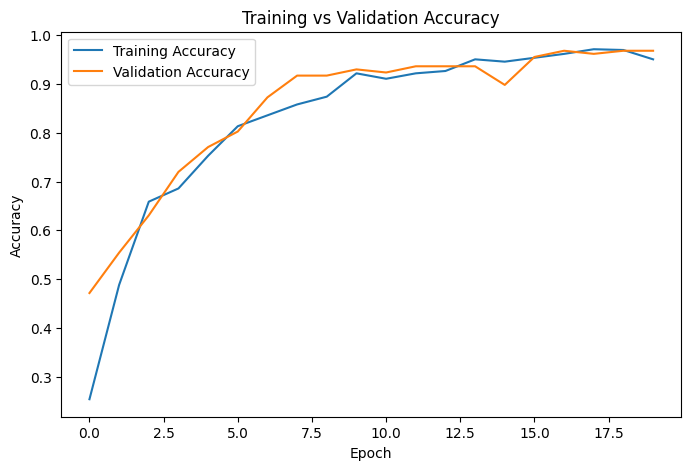

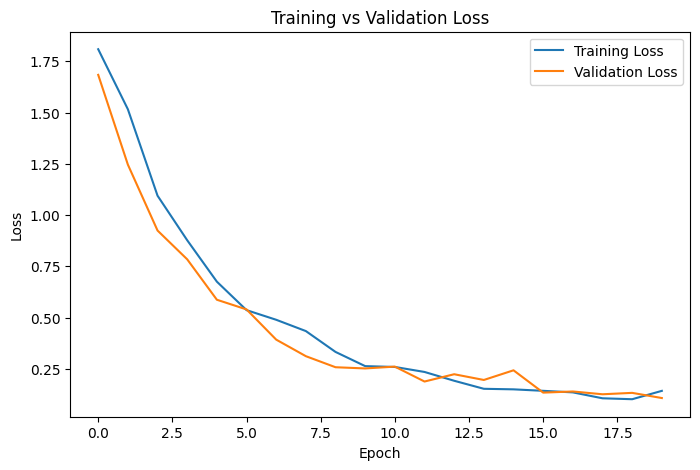

In [ ]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

**1. Training vs Validation Accuracy**
X-axis = Epoch → number of times the model learns from the training data.
Y-axis = Accuracy → how many predictions are correct.
Blue line = Training Accuracy → accuracy on training data.
Orange line = Validation Accuracy → accuracy on validation data.

**2. Training vs Validation Loss**
X-axis = Epoch
Y-axis = Loss → how much error the model is making.
Blue = Training Loss
Orange = Validation Loss

 In the accuracy graph, both training and validation accuracy increase as the epochs increase, which indicates that the model is learning the facial-expression patterns. In the loss graph, both training and validation loss decrease, indicating that the prediction error is reducing during training."

**STEP 15 — Save the Trained CNN Model**

In [ ]:
model.save("/content/facial_expression_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


Our model is trained now. We should save it, so we don't have to train the CNN again every time we want to test a new image.

**STEP 16 — Upload a Random Image & Detect the Face**

**MEDIAPIPE INTEGRATED**

In [ ]:
!pip install -q mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.9/37.9 MB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 13.2 MB/s eta 0:00:00


In [ ]:
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

print("MediaPipe imported successfully!")
print("Version:", mp.__version__)

MediaPipe imported successfully!
Version: 1.0.1


In [ ]:
!wget -q https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/1/blaze_face_short_range.tflite

import os
print("Model exists:", os.path.exists("blaze_face_short_range.tflite"))

Model exists: True


In [ ]:
base_options = python.BaseOptions(
    model_asset_path="blaze_face_short_range.tflite"
)

options = vision.FaceDetectorOptions(
    base_options=base_options,
    min_detection_confidence=0.5
)

detector = vision.FaceDetector.create_from_options(options)

print("Face detector ready!")

Face detector ready!


In [ ]:
print("Detector:", detector is not None)
print("Model:", model is not None)
print("Emotions:", emotions)

Detector: True
Model: True
Emotions: ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']


We use MediaPipe for face detection. It identifies the face in the uploaded image and provides its bounding box. We then crop the face and give the processed 48×48 grayscale image to our CNN for facial-expression classification.”

Saving Thamana.jpeg to Thamana (1).jpeg
✅ Face detected!


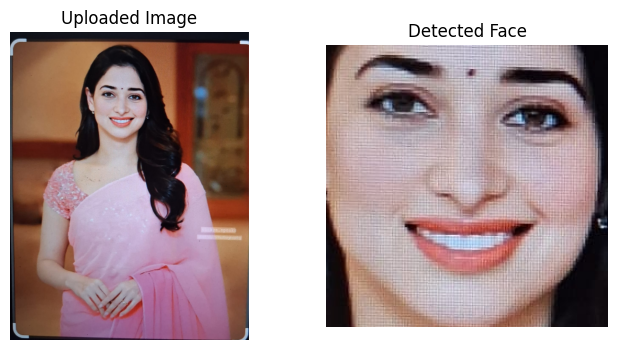

Predicted Expression: happy

Probabilities:
anger     : 0.00%
contempt  : 0.00%
disgust   : 0.01%
fear      : 0.00%
happy     : 99.89%
sadness   : 0.00%
surprise  : 0.09%


In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Upload image
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

# Read image
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert to MediaPipe image
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

# Detect face
result = detector.detect(mp_image)

if len(result.detections) == 0:
    print("❌ No face detected!")
else:
    print("✅ Face detected!")

    # Get first detected face
    bbox = result.detections[0].bounding_box

    x = max(0, bbox.origin_x)
    y = max(0, bbox.origin_y)
    w = bbox.width
    h = bbox.height

    # Crop face
    face_crop = image_rgb[y:y+h, x:x+w]

    # Preprocess for CNN
    face_gray = cv2.cvtColor(face_crop, cv2.COLOR_RGB2GRAY)
    face_resized = cv2.resize(face_gray, (48, 48))
    face_normalized = face_resized / 255.0
    face_input = face_normalized.reshape(1, 48, 48, 1)

    # CNN prediction
    predictions = model.predict(face_input, verbose=0)[0]

    predicted_index = np.argmax(predictions)
    predicted_emotion = emotions[predicted_index]

    # Display
    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(image_rgb)
    plt.title("Uploaded Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(face_crop)
    plt.title("Detected Face")
    plt.axis("off")

    plt.show()

    # Results
    print("Predicted Expression:", predicted_emotion)
    print("\nProbabilities:")

    for emotion, probability in zip(emotions, predictions):
        print(f"{emotion:10s}: {probability * 100:.2f}%")

**CNN ARCHITECTURE**

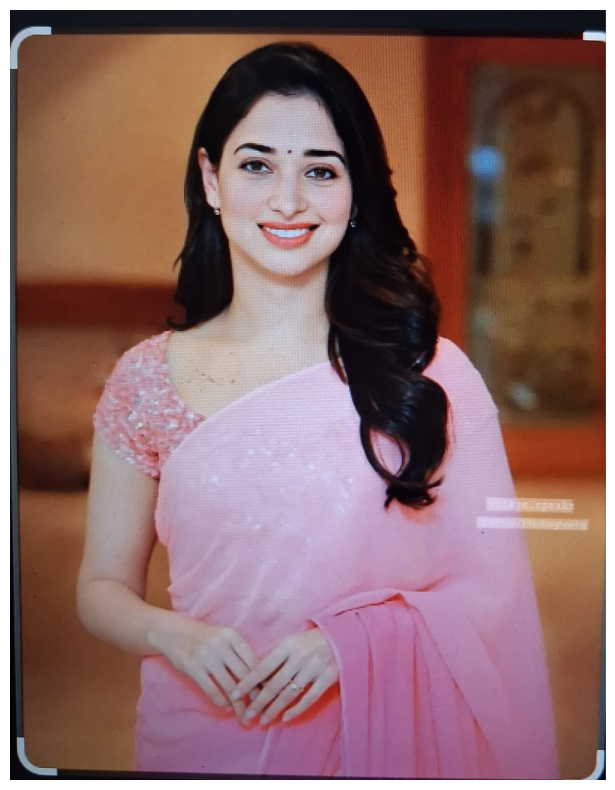

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open(list(uploaded.keys())[0])

plt.figure(figsize=(15, 10))
plt.imshow(image)
plt.axis("off")
plt.show()